# 01 — Full 5k panel: checks and setup


In [1]:
import logging
import h5py
import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import squidpy as sq
import cellcharter as cc
import matplotlib.pyplot as plt
import seaborn as sns
from anndata.io import read_elem
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

logging.getLogger('lightning.pytorch').setLevel(logging.ERROR)
logging.getLogger('pytorch_lightning').setLevel(logging.ERROR)

FULL = '../data/mtDNA_DSB_5k_clustered_annotation_with_rbd_2_cytetype_brain_novae4.companion.ready.h5ad'
OLD = '../data/adata_cellcharter.h5ad'          # 250-HVG object with the CellCharter run
OUT = '../data/adata_5k_cellcharter.h5ad'
RES = '../results/cellcharter'

SAMPLE, COND, COMP = 'sample_id', 'condition', 'compartment'
CT = 'cell_class_updated'        # annotation as delivered
CT_WORK = 'cell_class_work'      # working annotation (OL lineage split, see section 3)
TP = 'timepoint'                 # DOX removal timepoint (P21 / P60) = Xenium slide
RESP = 'responder_status'        # control / responder / non-responder (from CM_README.md, not derived here)

/home/anitag/anaconda3/envs/karospace311/lib/python3.13/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/home/anitag/anaconda3/envs/karospace311/lib/python3.13/site-packages/docrep/decorators.py:43: SyntaxWarning: 'show_progress_bar' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)


## 1. Load
The full object needs ~9 GB of RAM (X + counts). From the 250-HVG object only the needed pieces are read with h5py,
without loading its matrices.

In [2]:
adata = ad.read_h5ad(FULL)
print(adata)

h_old = h5py.File(OLD, 'r')
old_obs = pd.DataFrame({c: read_elem(h_old['obs'][c]) for c in [SAMPLE, CT, COMP, '_scvi_batch']},
                       index=read_elem(h_old['obs/_index']))
old_var = read_elem(h_old['var'])

AnnData object with n_obs × n_vars = 980474 × 5101
    obs: 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'run', 'n_genes_by_counts', 'n_counts', 'n_genes', 'leiden_0.5', 'leiden_1', 'leiden_2', 'cell_class', 'sample_id', 'age', 'sex', 'genotype', 'condition', 'cell_type', 'cell_id', 'rbd_domain_0.1', 'rbd_domain_0.2', 'rbd_domain_0.5', 'rbd_domain_1.0', 'RBD_compartment', 'RBD_compartment_simplified', 'leiden_1.5', 'leiden_2.1', 'leiden_2.3', 'leiden_2.5', 'leiden_3', 'cytetype_annotation_leiden_3', 'cytetype_cellOntologyTerm_leiden_3', 'novae_sid', 'neighborhood_valid', 'novae_leaves', 'novae_domains_15', 'novae_domains_30', 'novae_domains_25', 'novae_domains_20', 'novae_domains_50', 'cell_class_updated'
    var: 'n_cells_by_counts', 'mean_counts', 'pct_dropout_b

## 1. Oligodendrocyte states and microglia per mouse

,DA-Oligodendrocytes,Oligodendrocytes,COP/NFOL,OPC,Microglia,condition,timepoint
sample_id,,,,,,,
RB4620,0.0013,0.1565,0.0035,0.0211,0.0261,control,P21
RB4658,0.0009,0.1695,0.0041,0.0241,0.0270,control,P21
RB4676,0.0027,0.1711,0.0032,0.0249,0.0296,control,P21
RB4627,0.0637,0.0859,0.0037,0.0219,0.0320,mtDSB,P21
RB4630,0.0005,0.1647,0.0026,0.0219,0.0284,mtDSB,P21
RB4653,0.0010,0.1514,0.0042,0.0267,0.0265,mtDSB,P21
RB4282,0.0005,0.1739,0.0022,0.0205,0.0268,control,P60
RB4350,0.0040,0.1673,0.0026,0.0240,0.0300,control,P60
RB4498,0.0015,0.1743,0.0029,0.0232,0.0294,control,P60


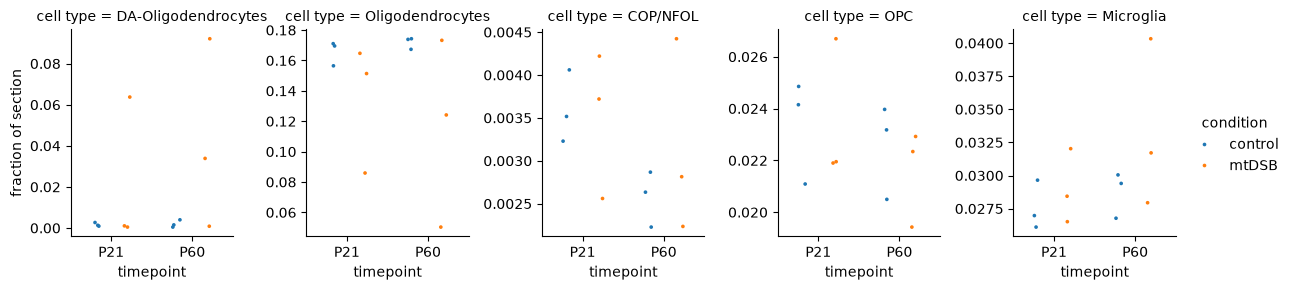

In [11]:
show = ['DA-Oligodendrocytes', 'Oligodendrocytes', 'COP/NFOL', 'OPC', 'Microglia']
frac = pd.crosstab(adata.obs[SAMPLE], adata.obs[CT_WORK], normalize='index')[show]
frac.columns = frac.columns.astype(str)    # categorical labels break .join in pandas 2.3
frac.index = frac.index.astype(str)
frac = frac.join(info[[COND, TP]]).sort_values([TP, COND])
display(frac.round(4))

long = frac.reset_index().melt(id_vars=[SAMPLE, COND, TP], var_name='cell type', value_name='fraction of section')
g = sns.catplot(data=long, x=TP, y='fraction of section', hue=COND, col='cell type', kind='strip',
                dodge=True, sharey=False, height=3, aspect=0.8, s=7)
g.savefig(f'{RES}/ol_states_microglia_per_mouse.png', dpi=150, bbox_inches='tight')

DA-OLs are abundant in only **3 of 6 mtDSB mice** (RB4627 P21 ≈ 6%, RB4401 P60 ≈ 3%, RB4405 P60 ≈ 9% of all cells),
and these mice have fewer mature OLs. This matches the responder calls in `CM_README.md` (finding 1):
- **Responders** RB4405, RB4401, RB4627: P(responder) > 0.99, from a pre-specified ATF4 / ISR gene set, classifiers that
  never saw the mouse, and the DA-OL share (three readouts that agree).
- **Non-responders** RB4403, RB4653 (P < 0.01) and **RB4630, borderline** (P = 0.17, possibly a weak responder).

How it is used here:
- The **primary** comparison stays mtDSB vs control, as planned.
- A **secondary** comparison, responders (3) vs controls (6), follows the CM analysis: exact permutation, 84 relabelings,
  min p = 0.012. Non-responders are shown in plots but not tested.

In [12]:
# responder calls from CM_README.md (finding 1, analysis/07); RB4630 is borderline (P = 0.17) -> non-responder here
RESPONDERS = ['RB4405', 'RB4401', 'RB4627']
status = np.where(adata.obs[COND] == 'control', 'control',
                  np.where(adata.obs[SAMPLE].isin(RESPONDERS), 'responder', 'non-responder'))
adata.obs[RESP] = pd.Categorical(status, categories=['control', 'non-responder', 'responder'])
info[RESP] = adata.obs.groupby(SAMPLE, observed=True)[RESP].first()
info

,condition,timepoint,sex,genotype,n_cells,responder_status
sample_id,,,,,,
RB4620,control,P21,male,mtPst1,88718,control
RB4658,control,P21,female,PlptTA,71184,control
RB4676,control,P21,female,PlptTA,81758,control
RB4627,mtDSB,P21,male,PlptTA:mtPst1,72848,responder
RB4630,mtDSB,P21,male,PlptTA:mtPst1,69913,non-responder
RB4653,mtDSB,P21,female,PlptTA:mtPst1,77245,non-responder
RB4282,control,P60,male,PlptTA,81721,control
RB4350,control,P60,male,PlptTA,72889,control
RB4498,control,P60,female,PlptTA,75676,control


## 2. Compartment names and comparison with the RBD compartments

ARI 0.506 | NMI 0.615


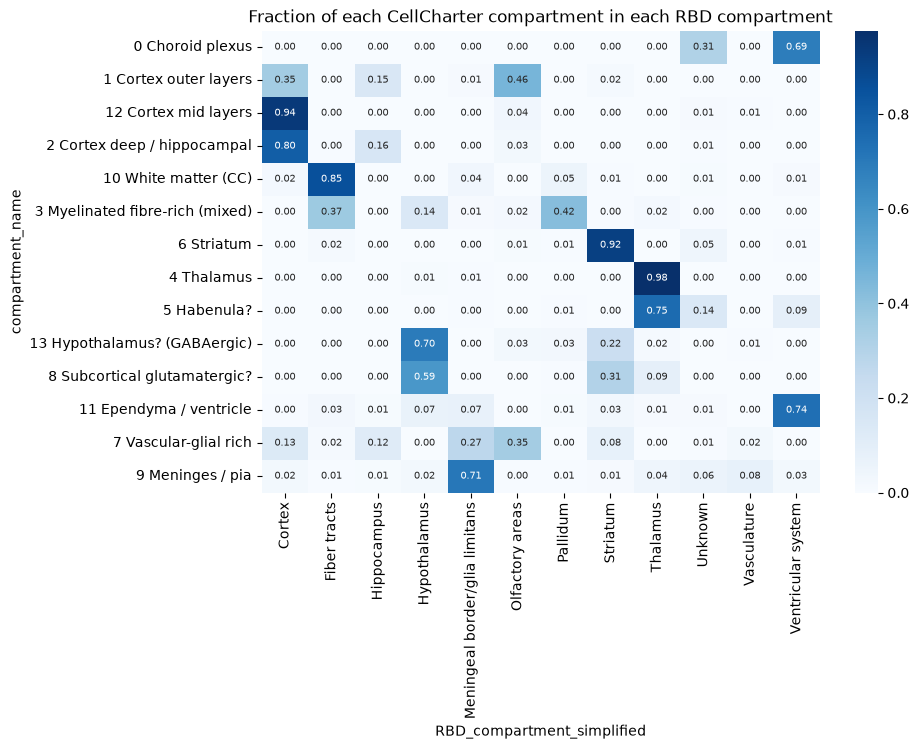

In [13]:
names = {
    '0': 'Choroid plexus', '1': 'Cortex outer layers', '12': 'Cortex mid layers', '2': 'Cortex deep / hippocampal',
    '10': 'White matter (CC)', '3': 'Myelinated fibre-rich (mixed)', '6': 'Striatum', '4': 'Thalamus',
    '5': 'Habenula?', '13': 'Hypothalamus? (GABAergic)', '8': 'Subcortical glutamatergic?',
    '11': 'Ependyma / ventricle', '7': 'Vascular-glial rich', '9': 'Meninges / pia',
}
adata.obs['compartment_name'] = pd.Categorical(adata.obs[COMP].astype(str).map(lambda c: f'{c} {names[c]}'),
                                               categories=[f'{c} {names[c]}' for c in names])

rbd = adata.obs['RBD_compartment_simplified'].astype(str)
print('ARI', round(adjusted_rand_score(rbd, adata.obs[COMP]), 3),
      '| NMI', round(normalized_mutual_info_score(rbd, adata.obs[COMP]), 3))

ct = pd.crosstab(adata.obs['compartment_name'], rbd, normalize='index')
fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(ct, cmap='Blues', annot=True, fmt='.2f', annot_kws={'size': 7}, ax=ax)
ax.set_title('Fraction of each CellCharter compartment in each RBD compartment')
fig.savefig(f'{RES}/crosstab_cellcharter_vs_rbd.png', dpi=150, bbox_inches='tight')

## 3. Marker genes on the full 5k panel
- Cell-level Wilcoxon p-values are hugely inflated (cells from the same mouse are not independent), so they are used **for
  ranking only**.
- Subsample to max 300 cells per compartment × section, so that large sections (RB4403 has ~2× the cells) do not dominate.

In [14]:
print('log1p:', adata.uns.get('log1p'), '| expm1 row sums (first cells):',
      np.expm1(adata.X[:5].toarray()).sum(1).round(1))

sub_idx = (adata.obs.groupby([COMP, SAMPLE], observed=True, group_keys=False)
           .apply(lambda d: d.sample(min(len(d), 300), random_state=0)).index)
mk = adata[sub_idx].copy()
print(mk.shape)

sc.tl.rank_genes_groups(mk, COMP, method='wilcoxon', pts=True)
markers = sc.get.rank_genes_groups_df(mk, group=None)
markers = markers[(markers['logfoldchanges'] > 1) & (markers['pct_nz_group'] > 0.25) & (markers['pvals_adj'] < 0.05)]
top = markers.sort_values(['group', 'scores'], ascending=[True, False]).groupby('group', observed=True).head(20)
top.to_csv(f'{RES}/markers_top20_per_compartment_5k.csv', index=False)
for gname, s in top.groupby('group', observed=True):
    print(f'{gname:>3} {names[str(gname)]:32s}', ', '.join(s['names'].head(12)))

log1p: {'base': None} | expm1 row sums (first cells): [815. 815. 815. 815. 815.]


/tmp/ipykernel_145825/4225965404.py:5: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda d: d.sample(min(len(d), 300), random_state=0)).index)


(50400, 5101)
  0 Choroid plexus                   Clic6, Kl, Igf2, Cab39l, Pdia3, Folr1, Rnaset2a, Sostdc1, Hspa5, Cldn2, Sulf1, Tgfbr3
  1 Cortex outer layers              Camk2a, Slc17a7, Hpcal4, Camk2b, Gria2, Ptk2b, Nptxr, Prkce, Ppp3r1, Sept5, Slc30a3, Cyfip2
 10 White matter (CC)                Mbp, Cnp, Mal, Ermn, Sept4, Cldn11, Car2, Aplp1, Mog, Qdpr, Ugt8a, Rnf13
 11 Ependyma / ventricle             Sox9, Mt2, Pltp, Foxj1, Ntrk2, Rsph1, Mlc1, Anxa2, Id4, Cd24a, Idh2, Gprc5b
 12 Cortex mid layers                Camk2a, Snap25, Cabp1, Atp2b2, Slc17a7, Sncb, Cyfip2, Gabra1, Stxbp1, Arc, Lingo1, Syn1
 13 Hypothalamus? (GABAergic)        Gap43, Ahi1, Impact, Hap1, Peg3, Slc6a11, Minar2, Slc32a1, Zcchc12, Gad2, Ndn, Disp2
  2 Cortex deep / hippocampal        Slc17a7, Hpcal4, Vxn, Snap25, Camk2a, Prkce, Syn1, Neurod6, Dnm1, Kif5c, Adcy1, Cyfip2
  3 Myelinated fibre-rich (mixed)    Mbp, Kif5a, Sept4, Cnp, Mal, Qdpr, Ermn, Ugt8a, Cldn11, Mog, Slc6a11, Car2
  4 Thalamus                

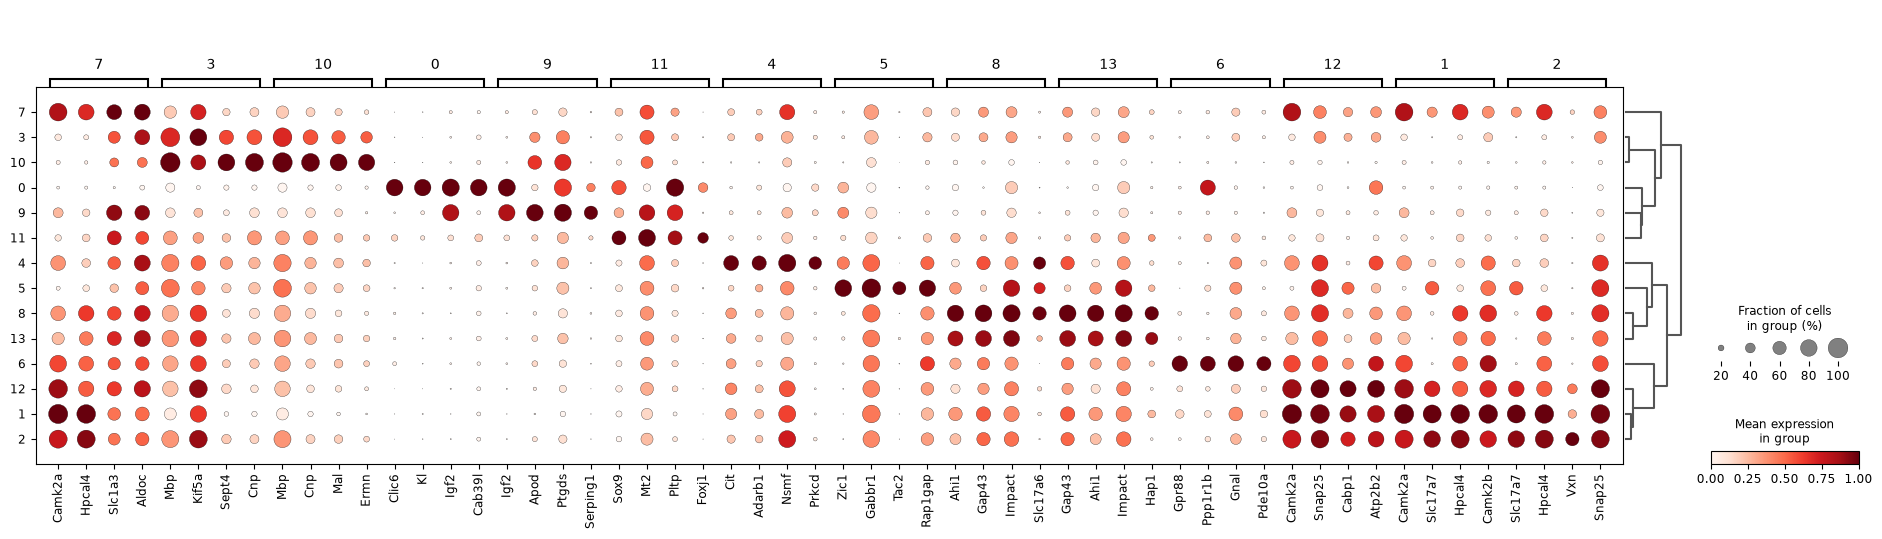

In [15]:
sc.pl.rank_genes_groups_dotplot(mk, n_genes=4, standard_scale='var', show=False)
plt.savefig(f'{RES}/markers_dotplot_5k.png', dpi=150, bbox_inches='tight')

not in panel: {'habenula': [], 'hypothalamus': [], 'STN / mammillary / ZI': [], 'thalamus / TRN': []}


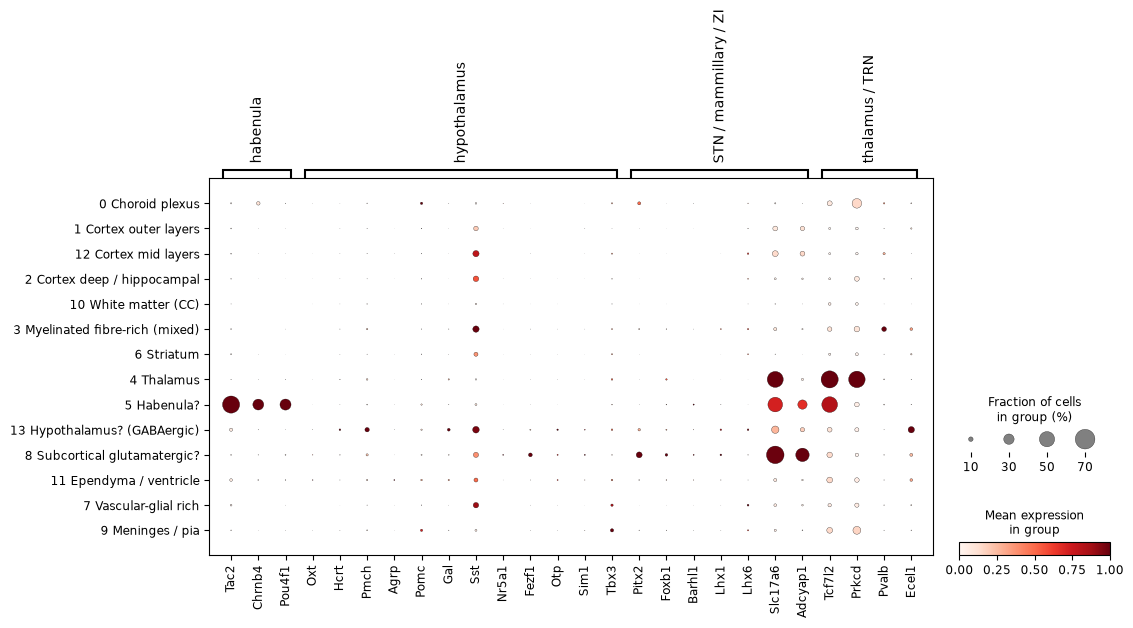

In [16]:
candidates = {
    'habenula': ['Tac2', 'Gpr151', 'Chrna3', 'Chrnb4', 'Nwd2', 'Pou4f1'],
    'hypothalamus': ['Avp', 'Oxt', 'Hcrt', 'Pmch', 'Agrp', 'Pomc', 'Gal', 'Sst', 'Nr5a1', 'Fezf1', 'Otp', 'Sim1', 'Tbx3'],
    'STN / mammillary / ZI': ['Pitx2', 'Foxb1', 'Barhl1', 'Lhx1', 'Lhx6', 'Slc17a6', 'Adcyap1'],
    'thalamus / TRN': ['Tcf7l2', 'Prkcd', 'Pvalb', 'Ecel1'],
}
candidates = {k: [g for g in v if g in mk.var_names] for k, v in candidates.items()}
print('not in panel:', {k: [g for g in v if g not in mk.var_names] for k, v in candidates.items()})
sc.pl.dotplot(mk, candidates, groupby='compartment_name', standard_scale='var', show=False)
plt.savefig(f'{RES}/anatomical_candidates_dotplot.png', dpi=150, bbox_inches='tight')
del mk

## 4. Save

In [17]:
h_old.close()
adata.write_h5ad(OUT)     # uncompressed, as the input (~10 GB); a new file, originals untouched